# Ćwiczenie 5: Przekształcenia lokalne w analizie obrazów medycznych
## Część 4: Filtry nieliniowe (Ochrona Krawędzi)

### 1. Ograniczenia filtracji liniowej
Jak widzieliśmy w Części 3, filtry uśredniające niszczą granice struktur, łącząc w jedną wartość matematyczną dwa skrajne obszary (np. kość i płuco). Co więcej, jeśli na obrazie pojawi się silny szum impulsowy (ekstremalnie biały piksel w czarnym tle), Gauss go nie usunie, a jedynie rozmyje w "szarą plamę".

### 2. Filtr medianowy (statystyka uporządkowana)
Rozwiązaniem jest **filtr medianowy**. Zamiast uśredniać z wagami, algorytm wykonuje nieliniową operację matematyczną:
1. Pobiera wartości wszystkich pikseli w masce (np. okno 3x3 daje 9 wartości).
2. Sortuje je od najmniejszej do największej.
3. Nową wartością piksela staje się wartość środkowa z posortowanej listy (mediana).

**Skutek:** Ekstremalne zaszumione piksele lądują na końcach listy i są ignorowane. Ostre przejścia tkankowe pozostają ostre.

### 3. Filtr bilateralny (zaawansowana ochrona)
Nowoczesne systemy AI i stacje robocze używają **filtrów bilateralnych**. Jest to ewolucja filtra Gaussa, która bierze pod uwagę dwa parametry rozkładu normalnego:
- Odległość przestrzenną pikseli ($\sigma_{\text{spatial}}$),
- **Różnicę ich jasności** ($\sigma_{\text{color}}$).
Jeśli algorytm natrafia na krawędź narządu (skok jasności $\sigma_{\text{color}}$), wstrzymuje wygładzanie w tym kierunku.

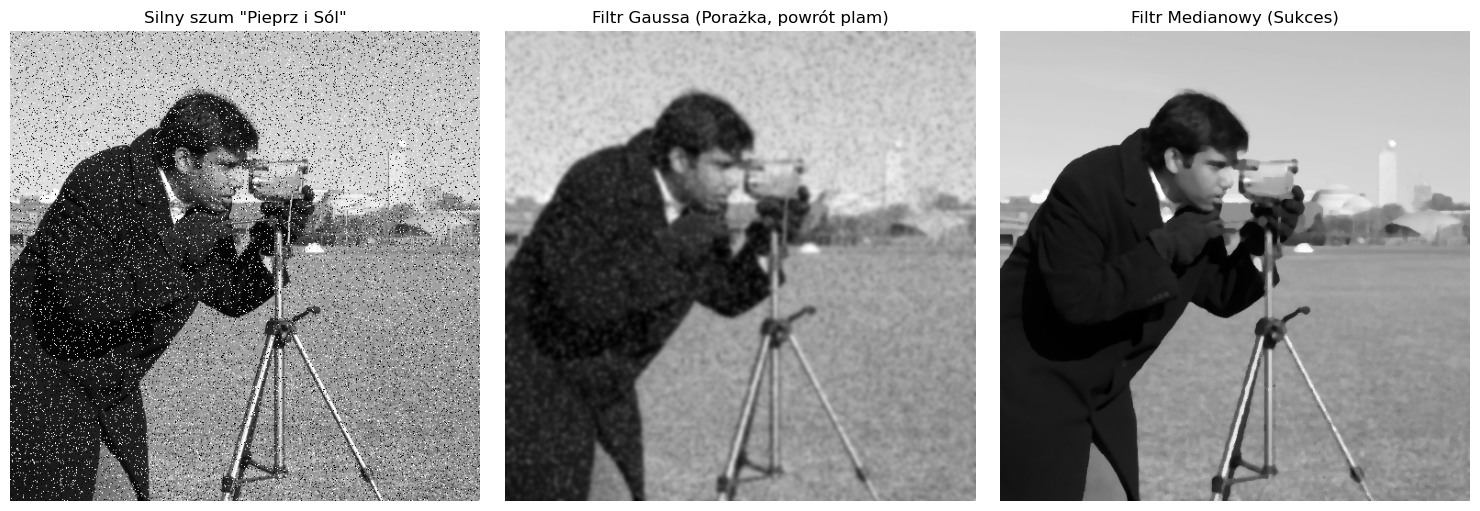

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, util, restoration
from skimage.morphology import disk

# Scenariusz 1: Szum impulsowy 
image_sp = util.random_noise(data.camera(), mode='s&p', amount=0.1)
gauss_on_sp = filters.gaussian(image_sp, sigma=2.0)
median_on_sp = filters.median(image_sp, disk(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_sp, cmap='gray')
axes[0].set_title('Silny szum "Pieprz i Sól"')

axes[1].imshow(gauss_on_sp, cmap='gray')
axes[1].set_title('Filtr Gaussa (Porażka, powrót plam)')

axes[2].imshow(median_on_sp, cmap='gray')
axes[2].set_title('Filtr Medianowy (Sukces)')

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

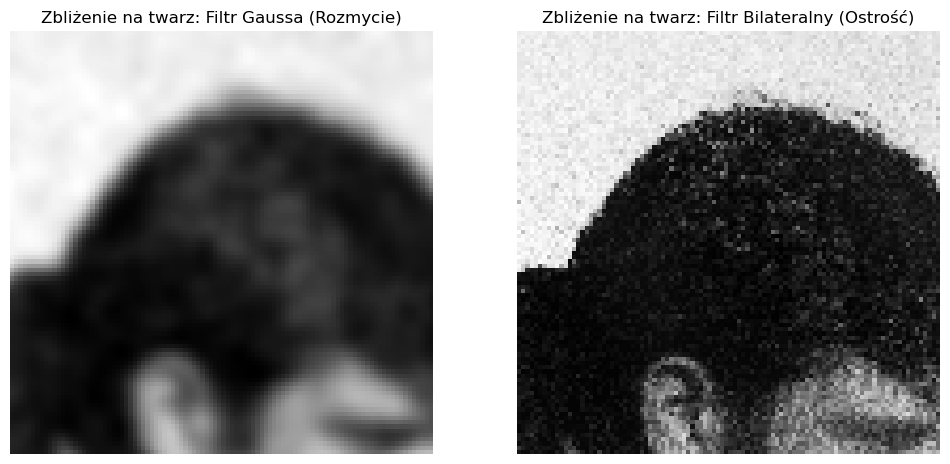

In [11]:
# Scenariusz 2: Szum Gaussa i siła Filtru Bilateralnego na krawędziach
image_g = util.random_noise(data.camera(), mode='gaussian', var=0.01)
img_gauss = filters.gaussian(image_g, sigma=2.0)
img_bilateral = restoration.denoise_bilateral(image_g, sigma_color=0.2, sigma_spatial=15, channel_axis=None)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_gauss[50:150, 150:250], cmap='gray')
axes[0].set_title('Zbliżenie na twarz: Filtr Gaussa (Rozmycie)')

axes[1].imshow(img_bilateral[50:150, 150:250], cmap='gray')
axes[1].set_title('Zbliżenie na twarz: Filtr Bilateralny (Ostrość)')

for ax in axes: ax.axis('off')
plt.show()